# Day 2: From Filters to CNNs

**COMP 395 — Deep Learning**

In this in-class assignment, you will:
1. Load an RGB image as a 3-channel PyTorch tensor
2. Implement max pooling from scratch
3. Use `nn.Conv2d` and see how its filters are stored
4. Build a complete CNN with `nn.Module` and trace tensor shapes through it
5. Train it on MNIST handwritten digits, then look at the filters it learned and the digits it gets wrong

**Paired work.** One person drives, one navigates. Switch roles at Part 3.

---

## Part 0: Setup

Create a folder for today's assignment and put **all three** files in it:
- this notebook (`Day2_Architecture.ipynb`)
- `astronaut.png`
- `cameraman.png` (the same image as yesterday)

Then open the notebook from that folder. Part 6 downloads the MNIST dataset (about 10 MB), so you'll need an internet connection at that point.

In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.io import read_image, ImageReadMode
from torchvision import datasets
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)

for f in ["astronaut.png", "cameraman.png"]:
    assert os.path.exists(f), (
        f"{f} not found. Put it in the same folder as this notebook, "
        "then restart the kernel and run from the top."
    )

# Reproducible initialization for the demonstrations.
torch.manual_seed(0)

## Part 1: RGB Images as Tensors

### 1.1 Loading a color image

Yesterday we loaded a grayscale image with `ImageReadMode.GRAY`. Asking for `ImageReadMode.RGB` gives us three channels instead of one.

In [2]:
rgb = read_image("astronaut.png", mode=ImageReadMode.RGB).float() / 255.0   # scale to [0, 1]

print(f"Shape: {rgb.shape}   (C, H, W)")
print(f"Value range: [{rgb.min().item()}, {rgb.max().item()}]")

Shape: torch.Size([3, 512, 512])   (C, H, W)
Value range: [0.0, 1.0]


### 1.2 Displaying it: the channels-first / channels-last mismatch

PyTorch stores images **channels first**: `(C, H, W)`. Matplotlib (and NumPy, PIL, and most image libraries) expect **channels last**: `(H, W, C)`. Passing the PyTorch tensor straight to `plt.imshow` raises an error about an invalid shape.

`permute(1, 2, 0)` reorders the dimensions: new dim 0 is old dim 1 (H), new dim 1 is old dim 2 (W), new dim 2 is old dim 0 (C).

You will get this wrong at some point. Everyone does.

For PyTorch:    (3, 512, 512)
For matplotlib: (512, 512, 3)


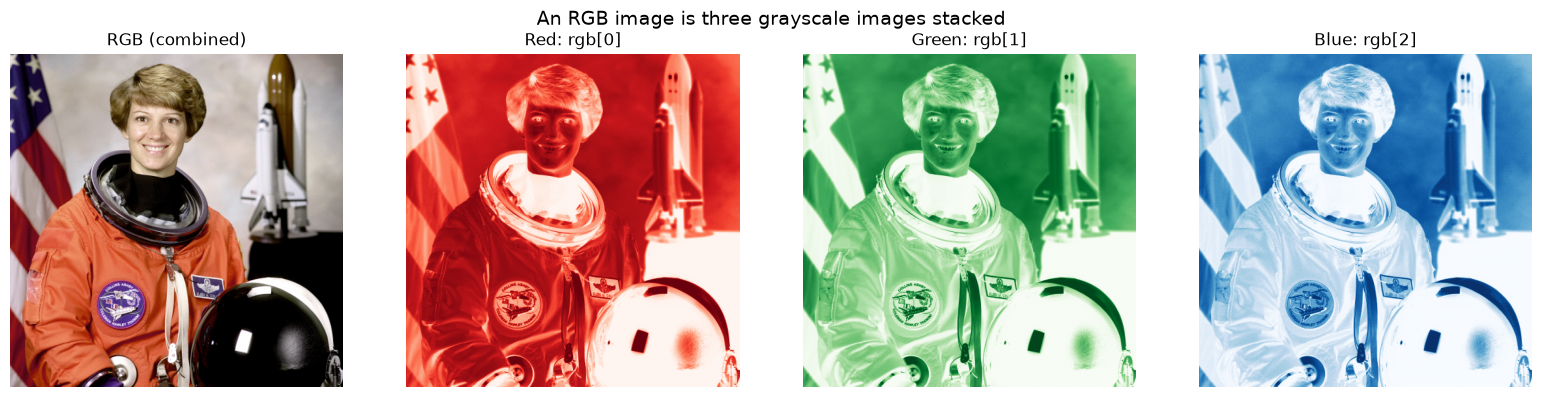

In [3]:
display_img = rgb.permute(1, 2, 0)    # (3, 512, 512) -> (512, 512, 3)
print(f"For PyTorch:    {tuple(rgb.shape)}")
print(f"For matplotlib: {tuple(display_img.shape)}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(display_img)
axes[0].set_title("RGB (combined)")

# Each channel is a 2D tensor: rgb[0] is red, rgb[1] is green, rgb[2] is blue
for c, (name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]):
    axes[c + 1].imshow(rgb[c], cmap=cmap)
    axes[c + 1].set_title(f"{name}: rgb[{c}]")

for ax in axes:
    ax.axis('off')
plt.suptitle("An RGB image is three grayscale images stacked", fontsize=14)
plt.tight_layout()
plt.show()

Each channel, `rgb[c]`, is a 2D tensor of shape `(512, 512)`: exactly the kind of thing you convolved yesterday.

### 1.3 Adding a batch dimension

`nn.Conv2d` and every other PyTorch layer expect a **batch** of images with shape `(N, C, H, W)`, even if the batch holds only one image.

In [4]:
batch = rgb.unsqueeze(0)
print(f"Single image: {tuple(rgb.shape)}   (C, H, W)")
print(f"Batch of one: {tuple(batch.shape)}   (N, C, H, W)")

Single image: (3, 512, 512)   (C, H, W)
Batch of one: (1, 3, 512, 512)   (N, C, H, W)


### ✏️ Quick check

What does `unsqueeze(0)` do, and why do layers want a batch dimension even for one image? (Hint: think about how you trained the MLP in Lab 4.)

---

## Part 2: Max Pooling from Scratch

Max pooling slides a window (usually 2×2) across a feature map and keeps only the largest value in each window. Unlike convolution, the windows **don't overlap**: they tile the feature map, so the output is half the size in each dimension.

### 2.1 Implement max pooling

We'll code this together. This is simpler than convolution: no kernel weights, just the max of each window.

**Hint:** for output position `(i, j)`, the window starts at row `i * pool_size` and column `j * pool_size`, not at `(i, j)`.

In [5]:
def max_pool2d(feature_map, pool_size=2):
    """
    Apply max pooling to a 2D feature map.

    Parameters
    ----------
    feature_map : torch.Tensor, shape (H, W)
    pool_size : int
        Size of the (non-overlapping) pooling window.

    Returns
    -------
    output : torch.Tensor, shape (H // pool_size, W // pool_size)
    """
    H, W = feature_map.shape
    out_h = H // pool_size
    out_w = W // pool_size
    output = feature_map.new_zeros((out_h, out_w))

    for i in range(out_h):
        for j in range(out_w):
            row = i * pool_size
            col = j * pool_size
            window = feature_map[row:row + pool_size, col:col + pool_size]
            output[i, j] = window.max()

    return output

### 2.2 Test your max pooling

In [6]:
test_input = torch.tensor([
    [1., 3., 2., 4.],
    [5., 6., 1., 2.],
    [7., 2., 8., 3.],
    [4., 1., 5., 6.],
])

pooled = max_pool2d(test_input, pool_size=2)

print("Input (4x4):")
print(test_input.int())
print("\nAfter 2x2 max pooling:")
print(pooled.int())
print("\nExpected: [[6, 4], [7, 8]]")

# PyTorch's built-in version expects (N, C, H, W), just like F.conv2d
builtin = F.max_pool2d(test_input[None, None], kernel_size=2).squeeze()
print(f"Matches F.max_pool2d? {torch.equal(pooled, builtin)}")

assert torch.equal(pooled, torch.tensor([[6., 4.], [7., 8.]]))
torch.testing.assert_close(pooled, builtin)

# Odd dimensions drop incomplete windows; negative values must remain negative.
odd_input = -torch.arange(1, 36, dtype=torch.float32).reshape(5, 7)
torch.testing.assert_close(
    max_pool2d(odd_input),
    F.max_pool2d(odd_input[None, None], kernel_size=2)[0, 0],
)


Input (4x4):
tensor([[1, 3, 2, 4],
        [5, 6, 1, 2],
        [7, 2, 8, 3],
        [4, 1, 5, 6]], dtype=torch.int32)

After 2x2 max pooling:
tensor([[6, 4],
        [7, 8]], dtype=torch.int32)

Expected: [[6, 4], [7, 8]]
Matches F.max_pool2d? True


### 2.3 Pooling a real feature map

We'll make an edge map of the cameraman with `F.conv2d` (the built-in convolution you timed yesterday), then pool it.

`x[None, None]` is shorthand for `x.unsqueeze(0).unsqueeze(0)`: it adds the batch and channel dimensions.

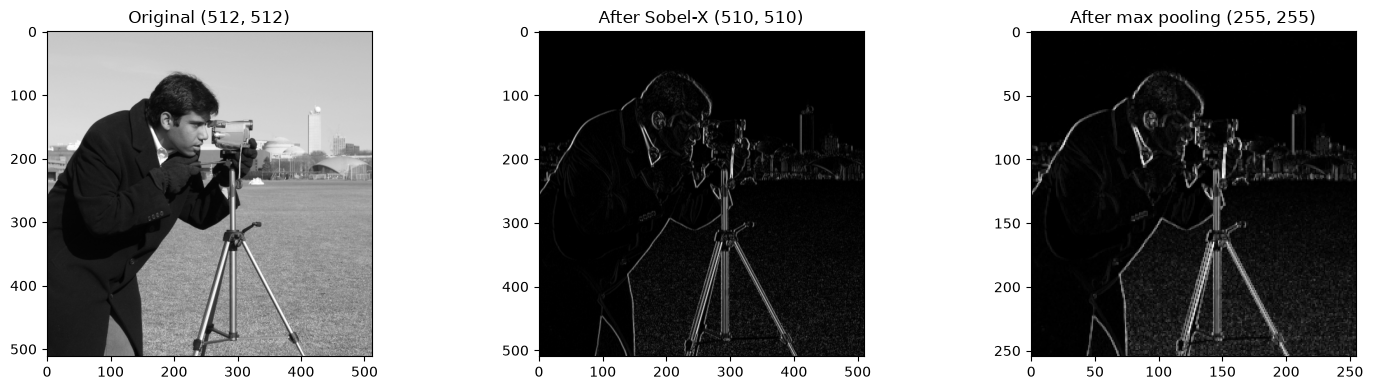

In [7]:
cam = read_image("cameraman.png", mode=ImageReadMode.GRAY).squeeze(0).float()   # (512, 512)

sobel_x = torch.tensor([[-1., 0., 1.],
                        [-2., 0., 2.],
                        [-1., 0., 1.]])

edge_map = F.conv2d(cam[None, None], sobel_x[None, None]).squeeze().abs()   # (510, 510)
pooled_edges = max_pool2d(edge_map, pool_size=2)                           # (255, 255)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (image, title) in zip(axes, [
    (cam, f"Original {tuple(cam.shape)}"),
    (edge_map, f"After Sobel-X {tuple(edge_map.shape)}"),
    (pooled_edges, f"After max pooling {tuple(pooled_edges.shape)}"),
]):
    ax.imshow(image, cmap='gray')
    ax.set_title(title)
plt.tight_layout()
plt.show()

### ✏️ Think–Pair–Share

1. Compare the pooled edge map to the original edge map. Are the edges mostly preserved, even though we threw away 3 out of every 4 values? Why does taking the *max* help?
2. If we applied 2×2 max pooling twice to a 512×512 image, what size would we end up with?

---

**🔄 Switch driver/navigator here.**

---

## Part 3: Using `nn.Conv2d`

`nn.Conv2d` does what your from-scratch code did, but it's fast, differentiable, and handles batches, multiple input channels, and multiple filters at once.

### 3.1 A layer of random filters

In [8]:
# 1 input channel (grayscale), 8 filters, each 3x3
conv = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1)

print(f"Weight shape: {tuple(conv.weight.shape)}   (out_channels, in_channels, kH, kW)")
print(f"Bias shape:   {tuple(conv.bias.shape)}")
print(f"Total parameters: {sum(p.numel() for p in conv.parameters())}   (8 * 1 * 3 * 3 + 8)")

Weight shape: (8, 1, 3, 3)   (out_channels, in_channels, kH, kW)
Bias shape:   (8,)
Total parameters: 80   (8 * 1 * 3 * 3 + 8)


The weights start out random, so these filters haven't learned to detect anything yet. Here's what they do to the cameraman. In Lab 5 you'll compare these to filters *after* training.

Input shape:  (1, 1, 512, 512)
Output shape: (1, 8, 512, 512)   (1 image, 8 feature maps)


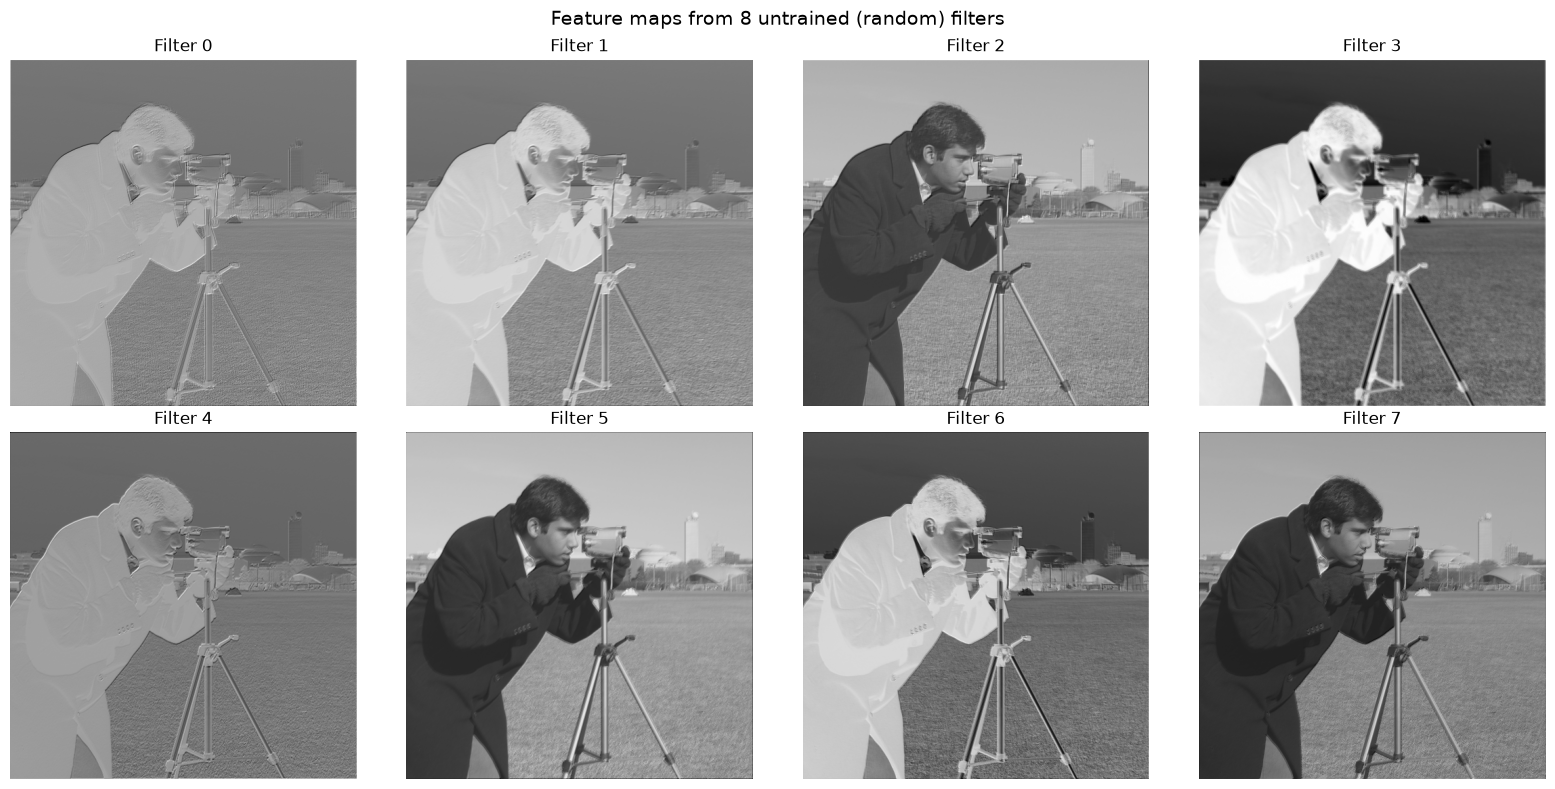

In [9]:
cam_batch = (cam / 255.0)[None, None]   # (1, 1, 512, 512)

with torch.no_grad():                     # just visualizing, no gradients needed
    feature_maps = conv(cam_batch)

print(f"Input shape:  {tuple(cam_batch.shape)}")
print(f"Output shape: {tuple(feature_maps.shape)}   (1 image, 8 feature maps)")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, i], cmap='gray')
    ax.set_title(f"Filter {i}")
    ax.axis('off')
plt.suptitle("Feature maps from 8 untrained (random) filters", fontsize=14)
plt.tight_layout()
plt.show()

### 3.2 Loading Sobel kernels into `nn.Conv2d`

A layer's filters live in `conv.weight`, shaped `(out_channels, in_channels, kH, kW)`. To see that, let's overwrite the random weights with the two Sobel kernels from yesterday.

Output shape: (1, 2, 510, 510)   (1 image, 2 feature maps)


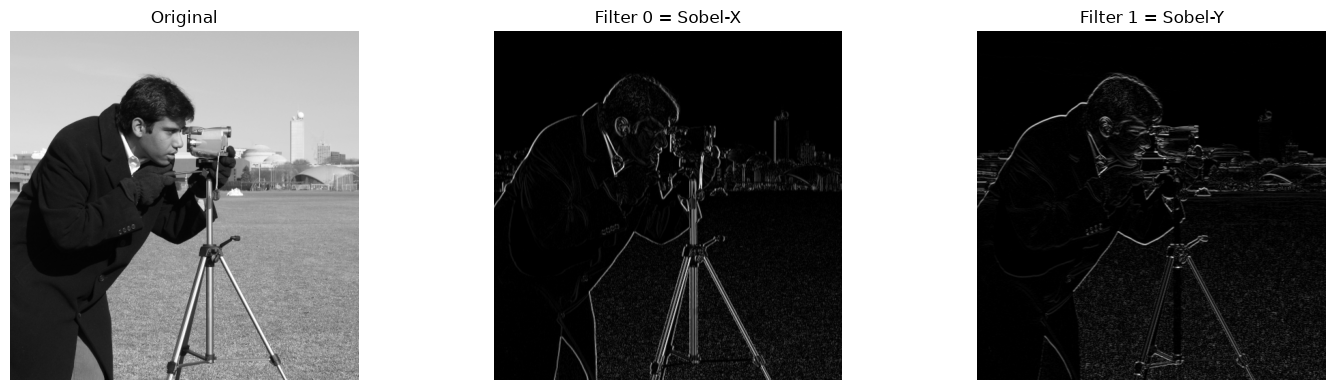

In [10]:
sobel_y = torch.tensor([[-1., -2., -1.],
                        [ 0.,  0.,  0.],
                        [ 1.,  2.,  1.]])

sobel_conv = nn.Conv2d(in_channels=1, out_channels=2, kernel_size=3, bias=False)

with torch.no_grad():
    sobel_conv.weight[0, 0] = sobel_x    # filter 0, input channel 0
    sobel_conv.weight[1, 0] = sobel_y    # filter 1, input channel 0
    sobel_output = sobel_conv(cam_batch)

print(f"Output shape: {tuple(sobel_output.shape)}   (1 image, 2 feature maps)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (image, title) in zip(axes, [
    (cam, "Original"),
    (sobel_output[0, 0].abs(), "Filter 0 = Sobel-X"),
    (sobel_output[0, 1].abs(), "Filter 1 = Sobel-Y"),
]):
    ax.imshow(image, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

Same operation as yesterday. The difference in a CNN is that nobody types in the weights: training adjusts them with `loss.backward()` and the optimizer, exactly like the weights of your MLP.

---

## Part 4: Building a CNN with `nn.Module`

This should feel familiar from Lab 4: you define layers in `__init__` and connect them in `forward`, just with new layer types. This network takes 28×28 grayscale images and outputs scores for 10 classes. You'll train it on MNIST in Lab 5.

In [11]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Convolutional layers (padding=1 keeps the spatial size the same)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)

        # Pooling and activation (no learnable parameters)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.relu = nn.ReLU()

        # Fully connected layers
        # After 2 rounds of conv + pool on 28x28: 28 -> 14 -> 7
        # With 32 channels: 32 * 7 * 7 = 1568 features
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):                        # x: (batch, 1, 28, 28)
        x = self.pool(self.relu(self.conv1(x)))  # (batch, 16, 14, 14)
        x = self.pool(self.relu(self.conv2(x)))  # (batch, 32, 7, 7)
        x = x.view(x.size(0), -1)                # (batch, 1568)  flatten
        x = self.relu(self.fc1(x))               # (batch, 128)
        x = self.fc2(x)                          # (batch, 10)    raw logits, no softmax
        return x


model = SimpleCNN()
print(model)
print()
for name, param in model.named_parameters():
    print(f"{name:12s} shape: {str(list(param.shape)):18s} params: {param.numel():>8,}")
print(f"\n{'Total':12s} {'':25s} params: {sum(p.numel() for p in model.parameters()):>8,}")

SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

conv1.weight shape: [16, 1, 3, 3]      params:      144
conv1.bias   shape: [16]               params:       16
conv2.weight shape: [32, 16, 3, 3]     params:    4,608
conv2.bias   shape: [32]               params:       32
fc1.weight   shape: [128, 1568]        params:  200,704
fc1.bias     shape: [128]              params:      128
fc2.weight   shape: [10, 128]          params:    1,280
fc2.bias     shape: [10]               params:       10

Total                                  params:  206,922


### ✏️ Think–Pair–Share: Where do the parameters live?

1. Which layer has the most parameters? Why does it need so many?
2. The two conv layers together have fewer than 5,000 parameters, while one fully connected layer from 784 pixels to 128 neurons would need 100,352. Why can conv layers be so small?
3. Suppose the input were a 224×224 image instead, with the same layers. What would happen to the size of `fc1`? (Work out the flattened size first.)

---

## Part 5: Trace the Shapes

Predicting the tensor shape at every point in a network is the most important CNN debugging skill. Run this trace and check each line against the comments in `forward`.

Two other ways to see the same shapes, both worth knowing: add `print(x.shape)` after each line of `forward`, or put `breakpoint()` as the first line of `forward` and run one forward pass. In the debugger, `n` runs one line, `x.shape` shows the result, and `c` continues.

In [12]:
x = torch.randn(4, 1, 28, 28)    # a dummy batch of 4 grayscale 28x28 images
print(f"Input:                  {tuple(x.shape)}")

x = model.conv1(x);             print(f"conv1 (1->16, pad=1):   {tuple(x.shape)}")
x = model.relu(x);              print(f"ReLU:                   {tuple(x.shape)}")
x = model.pool(x);              print(f"MaxPool 2x2:            {tuple(x.shape)}")
x = model.conv2(x);             print(f"conv2 (16->32, pad=1):  {tuple(x.shape)}")
x = model.relu(x);              print(f"ReLU:                   {tuple(x.shape)}")
x = model.pool(x);              print(f"MaxPool 2x2:            {tuple(x.shape)}")
x = x.view(x.size(0), -1);      print(f"Flatten:                {tuple(x.shape)}")
x = model.relu(model.fc1(x));   print(f"fc1 + ReLU:             {tuple(x.shape)}")
x = model.fc2(x);               print(f"fc2 (output):           {tuple(x.shape)}")

Input:                  (4, 1, 28, 28)
conv1 (1->16, pad=1):   (4, 16, 28, 28)
ReLU:                   (4, 16, 28, 28)
MaxPool 2x2:            (4, 16, 14, 14)
conv2 (16->32, pad=1):  (4, 32, 14, 14)
ReLU:                   (4, 32, 14, 14)
MaxPool 2x2:            (4, 32, 7, 7)
Flatten:                (4, 1568)
fc1 + ReLU:             (4, 128)
fc2 (output):           (4, 10)


### 5.1 Your turn: add a third conv block

Modify the network to add a **third** convolutional block (conv3 → ReLU → pool), with `out_channels=64`.

Answer these **before** coding:
1. What should `in_channels` be for conv3?
2. What is the spatial size after the third pool? (7 → ?) Careful: 7 is odd.
3. What should the input size of `fc1` be? (channels × height × width)

Then implement it and run the test at the bottom.

**Shape predictions:**
1. `conv3` needs `in_channels=32`, matching the output channels of `conv2`.
2. The third 2x2 pool with stride 2 reduces 7x7 to 3x3. The incomplete final row and column are dropped.
3. `fc1` needs `64 * 3 * 3 = 576` input features.


In [13]:
class DeeperCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()

        # After 3 pools: 28 -> 14 -> 7 -> 3.
        self.fc1 = nn.Linear(64 * 3 * 3, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x


deeper_model = DeeperCNN()
test_output = deeper_model(torch.randn(4, 1, 28, 28))
print(f"Output shape: {tuple(test_output.shape)}   (should be (4, 10))")

assert test_output.shape == (4, 10)

Output shape: (4, 10)   (should be (4, 10))


## Part 6: Train `SimpleCNN` on MNIST

MNIST is 70,000 handwritten digits (0–9), each a 28×28 grayscale image: 60,000 for training and 10,000 for testing. `torchvision` downloads it the first time you run the cell (about 10 MB).

### 6.1 Look at the digits

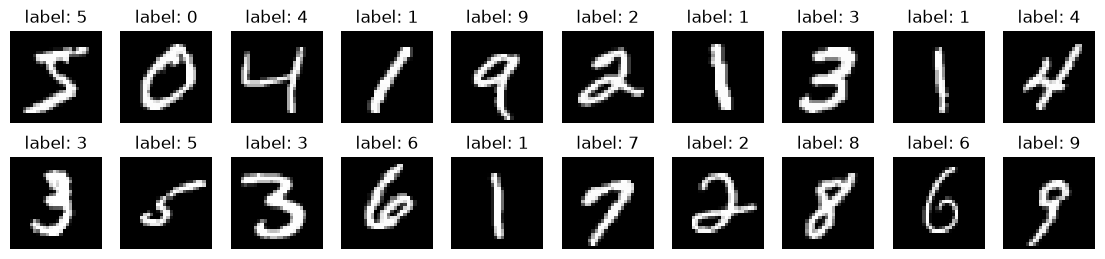

In [14]:
train_set = datasets.MNIST(root=".", train=True, download=True)
test_set = datasets.MNIST(root=".", train=False, download=True)

fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_set.data[i], cmap='gray')
    ax.set_title(f"label: {train_set.targets[i].item()}")
    ax.axis('off')
plt.show()

One digit: shape (28, 28), dtype torch.uint8, values 0-255


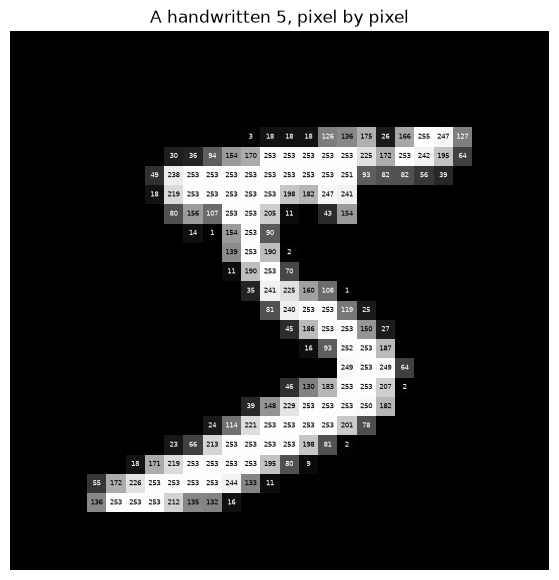

In [15]:
digit = train_set.data[0]
print(f"One digit: shape {tuple(digit.shape)}, dtype {digit.dtype}, values {digit.min().item()}-{digit.max().item()}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(digit, cmap='gray')
for r in range(28):
    for c in range(28):
        v = digit[r, c].item()
        if v > 0:
            ax.text(c, r, str(v), ha='center', va='center', fontsize=5, color='black' if v > 128 else 'white')
ax.set_title(f"A handwritten {train_set.targets[0].item()}, pixel by pixel")
ax.axis('off')
plt.show()

### 6.2 From pictures to tensors

`SimpleCNN` expects a batch of shape `(N, 1, 28, 28)` with float values. The dataset gives us `(N, 28, 28)` integers 0–255, so we add the channel dimension and scale to [0, 1].

In [16]:
X_train = train_set.data.float().unsqueeze(1) / 255.0
y_train = train_set.targets
X_test = test_set.data.float().unsqueeze(1) / 255.0
y_test = test_set.targets

print(f"Raw:     {tuple(train_set.data.shape)}  {train_set.data.dtype}")
print(f"X_train: {tuple(X_train.shape)}  {X_train.dtype}  values {X_train.min().item()}-{X_train.max().item()}")
print(f"y_train: {tuple(y_train.shape)}  first ten labels: {y_train[:10].tolist()}")
print(f"X_test:  {tuple(X_test.shape)}")

Raw:     (60000, 28, 28)  torch.uint8
X_train: (60000, 1, 28, 28)  torch.float32  values 0.0-1.0
y_train: (60000,)  first ten labels: [5, 0, 4, 1, 9, 2, 1, 3, 1, 4]
X_test:  (10000, 1, 28, 28)


### 6.3 Training loop

This is the `train` function from the sonar assignment. Two things change for a 10-class image task: the model outputs 10 scores per image instead of one, so there is no `.view(-1)`, and the loss is `CrossEntropyLoss`, which takes those raw scores and the integer label directly. `predict` picks the highest score with `argmax`, in batches of 1,000 so that 60,000 images don't have to fit through the network at once.

In [17]:
def train(model, loss_fn, optimizer, X_train, y_train, n_epochs=2, batch_size=64, seed=0):
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size,
                        shuffle=True, generator=torch.Generator().manual_seed(seed))
    losses = []
    device = next(model.parameters()).device

    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0.0

        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            y_hat = model(x_batch)
            loss = loss_fn(y_hat, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(y_batch)

        avg_loss = epoch_loss / len(y_train)
        losses.append(avg_loss)
        print(f'Epoch {epoch}, Loss: {avg_loss:.4f}')

    return losses


@torch.no_grad()
def predict(model, X, batch_size=1000):
    model.eval()
    device = next(model.parameters()).device
    predictions = []
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size].to(device)
        predictions.append(model(batch).argmax(dim=1).cpu())
    return torch.cat(predictions)


def accuracy(y_true, y_pred):
    return (y_true == y_pred).float().mean().item()

In [18]:
torch.manual_seed(0)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")
model = SimpleCNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

losses = train(model, loss_fn, optimizer, X_train, y_train, n_epochs=2, batch_size=64)

print(f"Training accuracy: {accuracy(y_train, predict(model, X_train)):.4f}")
print(f"Test accuracy:     {accuracy(y_test, predict(model, X_test)):.4f}")

Training device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


Epoch 0, Loss: 0.2284


Epoch 1, Loss: 0.0613


Training accuracy: 0.9874
Test accuracy:     0.9857


### 6.4 What did the filters learn?

Before training, `conv1`'s 16 filters were random noise (Part 3.1). Here they are now.

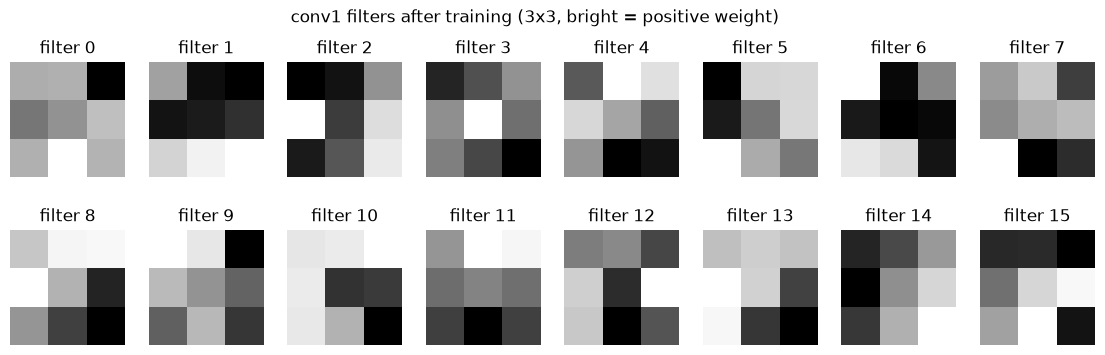

filter 0:
tensor([[ 0.1500,  0.1600, -0.4900],
        [-0.0500,  0.0500,  0.2200],
        [ 0.1600,  0.4600,  0.1700]])


In [19]:
filters = model.conv1.weight.detach().cpu()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(filters[i, 0], cmap='gray')
    ax.set_title(f"filter {i}")
    ax.axis('off')
plt.suptitle("conv1 filters after training (3x3, bright = positive weight)")
plt.show()

print("filter 0:")
print(filters[0, 0].round(decimals=2))

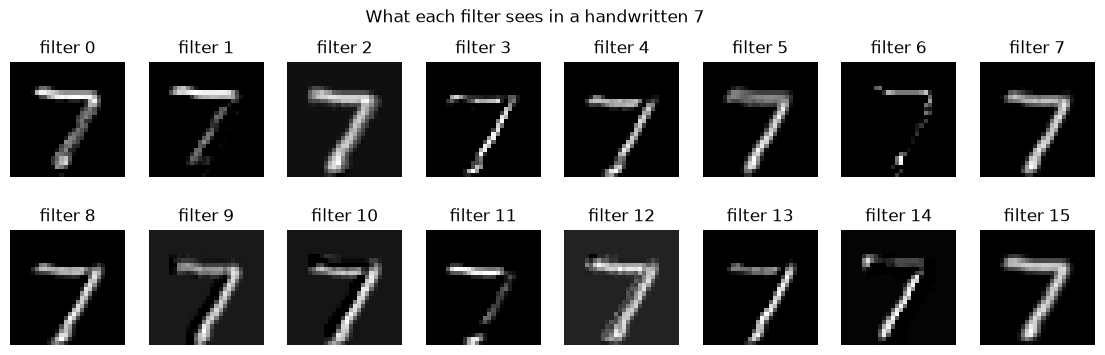

In [20]:
digit = X_test[0:1].to(next(model.parameters()).device)
with torch.no_grad():
    maps = model.relu(model.conv1(digit)).cpu()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(maps[0, i], cmap='gray')
    ax.set_title(f"filter {i}")
    ax.axis('off')
plt.suptitle(f"What each filter sees in a handwritten {y_test[0].item()}")
plt.show()

### 6.5 Which digits does it get wrong?

A **confusion matrix** counts, for every true digit (rows), what the model predicted (columns). A perfect model has nonzero counts only on the diagonal.

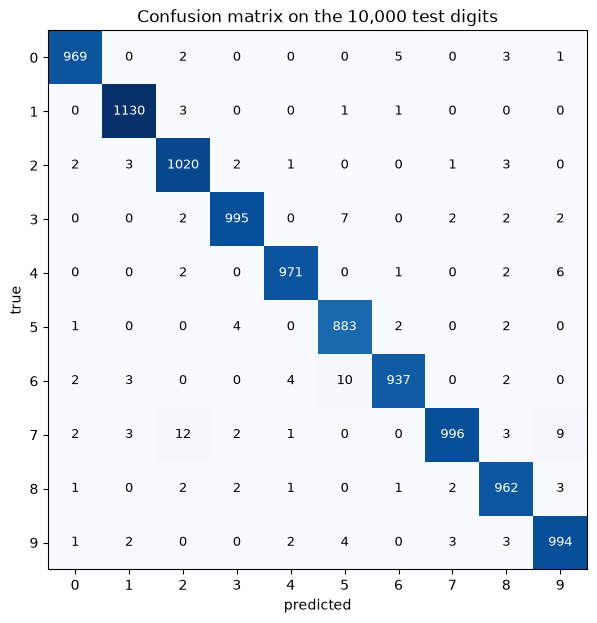

digit 0: 0.989 correct
digit 1: 0.996 correct
digit 2: 0.988 correct
digit 3: 0.985 correct
digit 4: 0.989 correct
digit 5: 0.990 correct
digit 6: 0.978 correct
digit 7: 0.969 correct
digit 8: 0.988 correct
digit 9: 0.985 correct

Largest off-diagonal entry (true -> predicted):
7 -> 2: 12 test images


In [21]:
y_pred = predict(model, X_test)
confusion = torch.zeros(10, 10, dtype=torch.int64)
for t, p in zip(y_test, y_pred):
    confusion[t, p] += 1

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(confusion, cmap='Blues')
for r in range(10):
    for c in range(10):
        ax.text(c, r, confusion[r, c].item(), ha='center', va='center',
                color='white' if confusion[r, c] > 500 else 'black', fontsize=9)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Confusion matrix on the 10,000 test digits")
plt.show()

per_digit = confusion.diag() / confusion.sum(dim=1)
for d in range(10):
    print(f"digit {d}: {per_digit[d]:.3f} correct")

assert confusion.sum().item() == len(y_test)
off_diagonal = confusion.clone()
off_diagonal.fill_diagonal_(0)
largest_count = off_diagonal.max().item()
largest_pairs = (off_diagonal == largest_count).nonzero()
print("\nLargest off-diagonal entry (true -> predicted):")
for true_digit, predicted_digit in largest_pairs.tolist():
    print(f"{true_digit} -> {predicted_digit}: {largest_count} test images")


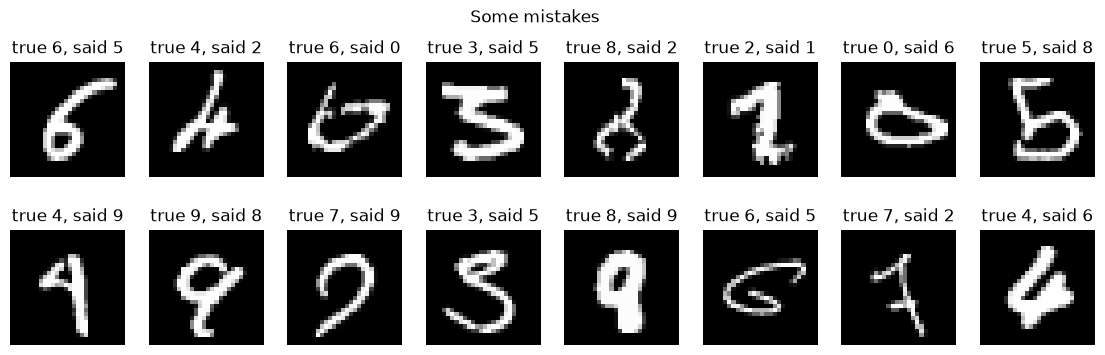

In [22]:
wrong = (y_pred != y_test).nonzero(as_tuple=True)[0][:16]

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in zip(wrong, axes.flat):
    ax.imshow(X_test[i, 0], cmap='gray')
    ax.set_title(f"true {y_test[i].item()}, said {y_pred[i].item()}")
    ax.axis('off')
plt.suptitle("Some mistakes")
plt.show()

### ✏️ Think–Pair–Share

1. Find the largest off-diagonal entry in the confusion matrix. Why would a CNN confuse those two digits?

   **Answer:** The largest off-diagonal entry is at true digit 7, predicted digit 2: 12 test images. Handwritten 7s and 2s can share a top horizontal stroke and a diagonal stroke. A curved or unusually shaped 7 can therefore resemble a 2. Pooling also reduces fine spatial detail, so small differences in the lower strokes may be harder for the network to distinguish.

2. Look at the mistakes. Are any of them ones *you* would get wrong?

   **Answer:** Yes, some are ambiguous enough that I could also misread them. For example, the image labeled "true 6, said 0" has a large closed loop that looks like a 0. The "true 7, said 9" example has a rounded top that resembles a 9. Other mistakes, such as the first 6 predicted as 5, look clearer to me, so the model's mistakes do not always match what a person would find difficult.

3. Do any of the learned filters look like the edge detectors from Day 1?

   **Answer:** Yes. Filter 11 has lighter weights near the top and darker weights along the bottom, resembling a horizontal edge detector. Filter 14 changes from dark on the left to light on the right, resembling a vertical edge detector. Like the Sobel filters from Day 1, these patterns respond to local changes in brightness. They are not exact Sobel kernels: their weights were learned from MNIST, and other filters show diagonal or more irregular patterns.

---


## Part 7: Exit Ticket

### ✏️ Answer these in your own words (graded for completeness, not correctness):

**1.** Without looking at your code, sketch `SimpleCNN` on paper: every layer in order, with the tensor shape after each one. (Paste a photo here if you like.)

*Your answer:*

**2.** How many learnable parameters does `nn.Conv2d(in_channels=16, out_channels=64, kernel_size=3)` have? Show your work, and don't forget the bias.

*Your answer:*

**3.** What is one thing that clicked for you today, and one thing you're still unsure about?

*Your answer:*

---

**Next:** Lab 5 builds on this network and training loop.